# CV-Pilot alerts and the Hugging Face Trainer, on real data

This notebook trains a **real pretrained image model** (a ResNet-18 from the Hugging Face Hub) on
real object crops cut from COCO128 photos, with the Hugging Face `Trainer`, while CV-Pilot records
the run and watches it. Then it breaks the training on purpose and shows the alerts arriving at a
local listener, with the exact messages. You will see five things:

1. The Hugging Face `Trainer` hook records a real run (loss, evaluation, saves, the end).
2. An injected **NaN loss** and a **loss plateau** send alerts to a webhook and a Slack-style webhook.
3. A real **regression** (YOLO11n at 640 px as the pinned baseline, the same model at 160 px as the
   candidate) sends an alert, and an equal candidate sends none.
4. **Dead channels** (a closed port, an endpoint that never answers, a redirect): the mean step time of
   a real training run is measured with and without them (a coarse check), and the cost of a single
   `log()` call is measured while alerts really fire (the precise one).
5. `cvpilot alerts check` replays a recorded run against a configuration and prints what would fire,
   sending nothing.

Every code cell is followed by a short **What this shows** note. The outputs were produced by really
running the notebook. It needs the internet once (about 60 MB) and takes several minutes on a CPU.

### Data, models and licences, and what the toy model can and cannot show

* **Data:** COCO128 (128 photos from COCO train2017). Annotations CC BY 4.0, each image keeps its own
  Flickr licence. Downloaded at run time into a cache outside the repository, never committed.
* **Detector (for the regression alert):** YOLO11n through the `ultralytics` package, **AGPL-3.0**
  (the optional extra, never a core dependency). Same download and SHA-256 pin as notebook 01.
* **Classifier:** `microsoft/resnet-18` from the Hugging Face Hub, **Apache-2.0**, 11 million
  parameters, weights as `safetensors` (no pickle), fetched at a pinned commit and checked by SHA-256.
  Training uses `transformers`, also Apache-2.0.
* **Honest limits.** The classifier sees a few hundred small crops for a few CPU epochs. It shows that
  the hook records a real `Trainer` run and that the alerts fire, are delivered, and cannot hurt the
  training loop. It says nothing about good thresholds for a long GPU job, about many processes, or
  about how often a real job produces false alarms. The numbers below are one laptop, one seed.

### Getting ready

A fresh scratch folder (so you can re-run from the top), and small helpers. `sh(...)` runs a command,
prints what it printed and its exit code, and hides the paths of this computer. Network settings of
the libraries are switched to offline for the training processes: they only read the files this
notebook downloaded and verified.

In [1]:
import contextlib
import hashlib
import json
import os
import re
import shlex
import shutil
import socket
import subprocess
import sys
import tempfile
import time
import urllib.error
import urllib.request
import warnings
import zipfile
from pathlib import Path

warnings.filterwarnings("ignore")

# Where downloads are cached. This is outside the repository and nothing in it is ever committed.
DATA = Path(
    os.environ.get("CVPILOT_NOTEBOOK_DATA") or Path(tempfile.gettempdir()) / "cvpilot-notebooks"
)
DATA.mkdir(parents=True, exist_ok=True)
# A fresh scratch folder for this run of the notebook: everything the notebook writes lives here.
WORK = Path(tempfile.mkdtemp(prefix="cvpilot-nb-"))
os.chdir(WORK)

os.environ["CVPILOT_STORE_DIR"] = "store"  # runs, metrics and evaluation results
os.environ["CVPILOT_CHECKPOINT_DIR"] = "ckpt"  # checkpoints
os.environ["CVPILOT_PROJECT"] = "coco128-yolo"  # default project of every cvpilot command
os.environ["CVPILOT_LOG_LEVEL"] = "WARNING"  # keeps this notebook's own Python calls quiet
os.environ["YOLO_VERBOSE"] = "False"  # silence the progress bars of Ultralytics
os.environ["YOLO_CONFIG_DIR"] = str(DATA / "ultralytics-config")  # keep Ultralytics settings here
(DATA / "ultralytics-config").mkdir(exist_ok=True)
os.environ.pop("CVPILOT_ENV", None)  # production behaviour until a cell says otherwise
os.environ.update(
    HF_HUB_OFFLINE="1",
    TRANSFORMERS_VERBOSITY="error",
    TOKENIZERS_PARALLELISM="false",
    PYTHONWARNINGS="ignore",
    HF_HUB_DISABLE_TELEMETRY="1",
    TQDM_DISABLE="1",
    HF_HUB_DISABLE_PROGRESS_BARS="1",
)  # the training processes never touch the network
TIMINGS = {}  # seconds per step, printed at the end

print("python", sys.version.split()[0], "| scratch folder: a fresh temporary directory")
print("downloads are cached in $CVPILOT_NOTEBOOK_DATA (default: <tmp>/cvpilot-notebooks)")

python 3.10.20 | scratch folder: a fresh temporary directory
downloads are cached in $CVPILOT_NOTEBOOK_DATA (default: <tmp>/cvpilot-notebooks)


**What this shows.** Everything the notebook writes goes into a temporary folder that is new on every run, with its own empty CV-Pilot store. Downloads are cached in a separate folder. The development setting `CVPILOT_ENV=dev` is *not* set: the first alert cells run with production rules.

In [2]:
_REPLACEMENTS = sorted(
    [
        (str(WORK.resolve()), "."),
        (str(WORK), "."),
        (str(DATA.resolve()), "$CVPILOT_NOTEBOOK_DATA"),
        (str(DATA), "$CVPILOT_NOTEBOOK_DATA"),
        (str(Path.home()), "~"),
        (socket.gethostname(), "<this-computer>"),
    ],
    key=lambda pair: -len(pair[0]),
)
_OTHER_PATHS = re.compile(r"/(?:Users|home|private|var|tmp|opt)/[^\s\"',:)]+")
_QUIET_FIELDS = {"logger", "request_id", "service", "env", "@timestamp", "level", "message"}
_CLI = "import sys; sys.argv[0] = 'cvpilot'; from cvpilot.cli.app import main; main()"


def scrub(text):
    """Hide the paths and the computer name of the machine that runs this notebook."""
    for old, new in _REPLACEMENTS:
        if old:
            text = text.replace(old, new)
    return _OTHER_PATHS.sub("<path>", text)


def log_summary(line):
    """cvpilot writes one JSON object per log line on stderr; show it as one short line."""
    try:
        event = json.loads(line)
    except ValueError:
        return "stderr: " + scrub(line)
    if not isinstance(event, dict):
        return "stderr: " + scrub(line)
    fields = " ".join(
        f"{key}={scrub(str(value))[:44]}"
        for key, value in event.items()
        if key not in _QUIET_FIELDS
    )
    return f"log[{event.get('level', '?')}] {event.get('message')} {fields}"


class Result:
    def __init__(self, code, out, err):
        self.code, self.out, self.err = code, out, err

    def json(self):
        return json.loads(self.out)


def sh(
    command, *, lines=40, log_lines=8, quiet=False, keep=False, env=None, expect=None, timeout=900
):
    """Run one command, print what it printed (paths hidden) and its exit code.

    `cvpilot ...` runs the command-line tool of this Python environment. Output that is not
    JSON on stderr is shown as it is; the JSON log lines are shortened to one line each.
    The result (exit code, output) is returned only with `keep=True` or `quiet=True`.
    """
    argv = shlex.split(command)
    if argv[0] == "cvpilot":
        argv = [sys.executable, "-c", _CLI, *argv[1:]]
    elif argv[0] == "python":
        argv[0] = sys.executable
    full_env = {**os.environ, "CVPILOT_LOG_LEVEL": "INFO", **(env or {})}
    proc = subprocess.run(  # noqa: S603
        argv, capture_output=True, text=True, cwd=WORK, env=full_env, timeout=timeout, check=False
    )
    result = Result(proc.returncode, scrub(proc.stdout), scrub(proc.stderr))
    if not quiet:
        print("$", scrub(command))
        out_lines = result.out.rstrip("\n").splitlines()
        for line in out_lines[:lines]:
            print(line[:180] + (" ..." if len(line) > 180 else ""))
        if len(out_lines) > lines:
            print(f"... ({len(out_lines) - lines} more lines)")
        err_lines = [ln for ln in proc.stderr.splitlines() if ln.strip()]
        for line in err_lines[:log_lines]:
            print(log_summary(line)[:200])
        if len(err_lines) > log_lines:
            print(f"... ({len(err_lines) - log_lines} more log lines)")
        print("exit code:", proc.returncode)
    if expect is not None and proc.returncode != expect:
        raise RuntimeError(f"expected exit code {expect}, got {proc.returncode}: {command}")
    return result if (keep or quiet) else None


@contextlib.contextmanager
def timed(label):
    start = time.perf_counter()
    yield
    TIMINGS[label] = round(time.perf_counter() - start, 1)
    print(f"[{label}: {TIMINGS[label]} s]")

**What this shows.** `sh()` runs a command-line tool or a script, shows the output and the exit code (0 success, 1 a check failed, 2 the tool was used wrongly). CV-Pilot writes one JSON log line per event on a separate channel; the helper shortens each to one `log[...]` line.

In [3]:
sh("cvpilot --version")
sh("cvpilot doctor")

$ cvpilot --version
cvpilot 0.1.0
exit code: 0


$ cvpilot doctor
ok
log[INFO] doctor_completed status=ok package_version=0.1.0 python_version=3.10.20
exit code: 0


**What this shows.** The install works: `doctor` prints `ok`, exit code 0.

## 1. Get the real data, the detector and the Hugging Face model

### Checking what we download

The COCO128 and YOLO11n downloads come from GitHub release assets of `ultralytics/assets` over `https`, with a size limit and a timeout, into a temporary file that is renamed only after the check.

* **Pinned fingerprints.** The expected SHA-256 of each file is written into the next cell. A file with a different digest is deleted and the notebook stops, before anything is unpacked or loaded; a cached file that does not match is never reused. GitHub publishes no digest for these two assets (the release API returns `digest: null`), so the pins are **trust on first use**, cross-checked in two ways: the file sizes equal the sizes the release API reports (6,983,030 and 5,613,764 bytes), and downloading both files a second time gave identical digests. To update a pin after a deliberate upstream change, download the new file, review it, and replace the constant.
* **Safe unpacking.** The zip is never extracted with `extractall`. Every member is checked first (no absolute path, no `..`, no symlink or special file, at most 1000 files and 50 MB in total, compression ratio at most 20) and written into a fresh folder.
* **A `.pt` file is a pickle.** Loading a PyTorch `.pt` file can run arbitrary code, so the YOLO11n weights are loaded only after the digest check passed. The checkpoints that *we* write (the classifier in this notebook) use CV-Pilot's `safetensors` format, which contains only numbers and can never run code.

In [4]:
COCO128_URL = "https://github.com/ultralytics/assets/releases/download/v0.0.0/coco128.zip"
WEIGHTS_URL = "https://github.com/ultralytics/assets/releases/download/v8.3.0/yolo11n.pt"
# Pinned SHA-256 of every download. A file with any other digest is deleted and the notebook stops.
PINNED_SHA256 = {
    "coco128.zip": "61e5e3028863d8ffc3b81d6a514603954889f0edd5e4b44c4ce60b2da99aeb8e",
    "yolo11n.pt": "0ebbc80d4a7680d14987a577cd21342b65ecfd94632bd9a8da63ae6417644ee1",
}
MAX_DOWNLOAD_BYTES = {"coco128.zip": 20_000_000, "yolo11n.pt": 20_000_000}
ZIP_LIMITS = {"files": 1000, "bytes": 50_000_000, "ratio": 20}


def sha256_of(path):
    digest = hashlib.sha256()
    with open(path, "rb") as handle:
        for chunk in iter(lambda: handle.read(1 << 20), b""):
            digest.update(chunk)
    return digest.hexdigest()


def fetch(url, name):
    """Download over https into the cache (bounded, via a temporary file) and check the SHA-256.

    A cached file with the wrong digest is deleted and fetched again; a download with the wrong
    digest is deleted and raises. Nothing is unpacked or loaded before this check passes."""
    dest = DATA / name
    if dest.exists() and sha256_of(dest) != PINNED_SHA256[name]:
        dest.unlink()  # never reuse a cached file that does not match
    if not dest.exists():
        if not url.startswith("https://"):
            raise ValueError("only https downloads are allowed")
        part = dest.with_name(name + ".part")
        try:
            with urllib.request.urlopen(url, timeout=60) as response, open(part, "wb") as out:  # noqa: S310
                total = 0
                while chunk := response.read(1 << 20):
                    total += len(chunk)
                    if total > MAX_DOWNLOAD_BYTES[name]:
                        raise RuntimeError(
                            f"{name} is larger than {MAX_DOWNLOAD_BYTES[name]} bytes"
                        )
                    out.write(chunk)
        except (urllib.error.URLError, TimeoutError, OSError) as exc:
            part.unlink(missing_ok=True)
            raise RuntimeError(
                f"Could not download {name} ({type(exc).__name__}). This notebook needs the "
                f"internet once. Download {url} yourself, put the file in the folder named by "
                "CVPILOT_NOTEBOOK_DATA (default: <tmp>/cvpilot-notebooks) and run this cell again."
            ) from None
        except RuntimeError:
            part.unlink(missing_ok=True)
            raise
        digest = sha256_of(part)
        if digest != PINNED_SHA256[name]:
            part.unlink()
            raise RuntimeError(f"{name}: SHA-256 {digest} is not the pinned {PINNED_SHA256[name]}")
        part.replace(dest)  # atomic: a half-downloaded file never has the final name
    print(
        f"{name:12s} {dest.stat().st_size / 1e6:5.1f} MB  sha256 {sha256_of(dest)}  (matches the pin)"
    )
    return dest


def safe_unzip(zip_path, target):
    """Unpack into a new folder after checking every member; never `extractall`."""
    if target.exists():
        return
    staging = Path(tempfile.mkdtemp(dir=DATA, prefix="unzip-"))
    with zipfile.ZipFile(zip_path) as archive:
        members = archive.infolist()
        too_big = sum(m.file_size for m in members) > ZIP_LIMITS["bytes"]
        if len(members) > ZIP_LIMITS["files"] or too_big:
            raise RuntimeError("the archive has too many files or is too large")
        for member in members:
            name = Path(member.filename)
            mode = member.external_attr >> 16
            if name.is_absolute() or ".." in name.parts or "\\" in member.filename:
                raise RuntimeError(f"unsafe name in the archive: {member.filename}")
            if mode and (mode & 0o170000) not in (0o100000, 0o040000):
                raise RuntimeError(f"not a plain file or folder: {member.filename}")
            ratio = member.file_size / max(member.compress_size, 1)
            if ratio > ZIP_LIMITS["ratio"]:
                raise RuntimeError(f"suspicious compression ratio: {member.filename}")
        for member in members:
            out = staging / member.filename
            if member.is_dir():
                out.mkdir(parents=True, exist_ok=True)
                continue
            out.parent.mkdir(parents=True, exist_ok=True)
            with archive.open(member) as src, open(out, "wb") as dst:
                shutil.copyfileobj(src, dst)
    staging.rename(target)


coco_zip = fetch(COCO128_URL, "coco128.zip")
weights_path = fetch(WEIGHTS_URL, "yolo11n.pt")  # a pickle: only loaded after the check above
COCO_DIR = DATA / "coco128-unpacked"
safe_unzip(coco_zip, COCO_DIR)
COCO_ROOT = COCO_DIR / "coco128"
IMAGES = sorted((COCO_ROOT / "images" / "train2017").glob("*.jpg"))
print(f"{len(IMAGES)} images in $CVPILOT_NOTEBOOK_DATA/coco128-unpacked/coco128/images/train2017")

coco128.zip    7.0 MB  sha256 61e5e3028863d8ffc3b81d6a514603954889f0edd5e4b44c4ce60b2da99aeb8e  (matches the pin)
yolo11n.pt     5.6 MB  sha256 0ebbc80d4a7680d14987a577cd21342b65ecfd94632bd9a8da63ae6417644ee1  (matches the pin)
128 images in $CVPILOT_NOTEBOOK_DATA/coco128-unpacked/coco128/images/train2017


**What this shows.** COCO128 and the YOLO11n weights were fetched (or found in the cache), their SHA-256 matched the pins, and only then were they unpacked. A mismatch would stop the notebook.

### The Hugging Face model: where each pin comes from

The weights come from `https://huggingface.co/microsoft/resnet-18` at one **commit**
(`65a5785d9156231087c481e0c7dd33a5ff6f7e3e`, "Update README.md", 2024-04-08), never a branch name that
can move. The Hub's file listing for that commit (`/api/models/microsoft/resnet-18/tree/<commit>`) says
the licence tag is `apache-2.0` and gives, for the weights, the SHA-256 the Hub computed
(`lfs.oid`, an independent source) and for `config.json` the git blob id (SHA-1). The notebook pins:

* `model.safetensors`: SHA-256 `1cf00ee4...b126`, equal to the Hub's `lfs.oid`, 46,812,324 bytes.
* `config.json`: SHA-256 `11a01bcc...6d22` (computed from the downloaded bytes) and, as a second check,
  the git blob id `be9ec1cb...3d` that the notebook recomputes and compares with the Hub's.

The same `fetch()` as above does the download: https only, a timeout, a size limit, a temporary file,
a digest check before the final name exists. The model is then loaded from the local folder only,
with `use_safetensors=True`, `trust_remote_code=False` and the Hub switched to offline.

In [5]:
HF_REPO = "microsoft/resnet-18"
HF_REVISION = "65a5785d9156231087c481e0c7dd33a5ff6f7e3e"  # a commit id, not a branch name
HF_BASE = f"https://huggingface.co/{HF_REPO}/resolve/{HF_REVISION}"
# SHA-256 pins. The weights' pin is the Hub's own lfs.oid for this commit; the config's was
# computed from the downloaded bytes and cross-checked against the Hub's git blob id below.
PINNED_SHA256.update(
    {
        "resnet18-model.safetensors": "1cf00ee468998c23d084361b02cffadabacb5074105564c596b8079f77ecb126",
        "resnet18-config.json": "11a01bcc873444bb433140e5f30f3687356641ed923266d738eef1c3438f6d22",
    }
)
MAX_DOWNLOAD_BYTES.update(
    {"resnet18-model.safetensors": 60_000_000, "resnet18-config.json": 200_000}
)
GIT_BLOB_ID = {
    "resnet18-config.json": "be9ec1cb232f596559a0c780dedcf3d42fe11613"
}  # from the Hub listing

hf_weights = fetch(f"{HF_BASE}/model.safetensors", "resnet18-model.safetensors")
hf_config = fetch(f"{HF_BASE}/config.json", "resnet18-config.json")
config_bytes = hf_config.read_bytes()
blob = hashlib.sha1(b"blob %d\0" % len(config_bytes) + config_bytes).hexdigest()  # noqa: S324
if blob != GIT_BLOB_ID["resnet18-config.json"]:
    raise RuntimeError("config.json differs from the Hub's git blob id")
print("config.json git blob id matches the Hub listing:", blob[:12] + "...")

HF_MODEL_DIR = DATA / "resnet18-pinned"
if not HF_MODEL_DIR.exists():
    staging = Path(tempfile.mkdtemp(dir=DATA, prefix="hf-"))
    shutil.copyfile(hf_weights, staging / "model.safetensors")
    shutil.copyfile(hf_config, staging / "config.json")
    staging.rename(HF_MODEL_DIR)
from safetensors import safe_open

with safe_open(str(HF_MODEL_DIR / "model.safetensors"), framework="np") as handle:
    print(
        f"model.safetensors holds {len(list(handle.keys()))} tensors and no code (safetensors format)"
    )
os.environ["HF_MODEL_DIR"] = str(HF_MODEL_DIR)
INJECT_STEP = 8  # the step at which the NaN is injected (the training script is told the same)

resnet18-model.safetensors  46.8 MB  sha256 1cf00ee468998c23d084361b02cffadabacb5074105564c596b8079f77ecb126  (matches the pin)
resnet18-config.json   0.1 MB  sha256 11a01bcc873444bb433140e5f30f3687356641ed923266d738eef1c3438f6d22  (matches the pin)
config.json git blob id matches the Hub listing: be9ec1cb232f...
model.safetensors holds 122 tensors and no code (safetensors format)


**What this shows.** Two Hub files were downloaded at the pinned commit and matched their SHA-256 pins; the config also matches the Hub's own blob id; the weights are a plain tensor file. Nothing was unpacked, imported or executed from them yet.

In [6]:
import numpy as np
import pyarrow as pa
import pyarrow.parquet as pq
from PIL import Image

with timed("import torch and ultralytics, load YOLO11n"):
    import torch
    import ultralytics
    from ultralytics import YOLO

    ultralytics.settings.update({"sync": False})  # no usage reporting from this notebook
    MODEL = YOLO(str(weights_path))
NAMES = [MODEL.names[i] for i in range(len(MODEL.names))]
Path("classes.txt").write_text("\n".join(NAMES) + "\n")  # one class name per line, in id order
print(f"torch {torch.__version__}, ultralytics {ultralytics.__version__}, {len(NAMES)} classes")
print("device used for the detector: cpu")

[import torch and ultralytics, load YOLO11n: 1.9 s]
torch 2.14.1, ultralytics 8.4.123, 80 classes
device used for the detector: cpu


**What this shows.** The detector (used for the regression alert in section 6) is loaded on the CPU, after its digest check, and the 80 class names are saved in id order.

In [7]:
def yolo_ground_truth(root):
    """COCO128 labels are YOLO text files: `class x_center y_center width height`, all as
    fractions of the image. CV-Pilot wants pixel corners, one row per box."""
    cols = {k: [] for k in ("image_id", "cls", "x1", "y1", "x2", "y2", "width", "height")}
    for image in IMAGES:
        with Image.open(image) as handle:
            width, height = handle.size
        label = root / "labels" / "train2017" / f"{image.stem}.txt"
        lines = (
            label.read_text().splitlines() if label.exists() else []
        )  # a missing file: no objects
        boxes = [ln.split() for ln in lines if ln.strip()]
        if not boxes:  # an image with no objects: one row whose class and box are empty
            boxes = [[None] * 5]
        for cls, xc, yc, bw, bh in boxes:
            row = dict(image_id=image.stem, width=width, height=height)
            if cls is None:
                row.update(cls=None, x1=None, y1=None, x2=None, y2=None)
            else:
                xc, yc, bw, bh = (
                    float(xc) * width,
                    float(yc) * height,
                    float(bw) * width,
                    float(bh) * height,
                )
                row.update(
                    cls=int(cls), x1=xc - bw / 2, y1=yc - bh / 2, x2=xc + bw / 2, y2=yc + bh / 2
                )
            for key, value in row.items():
                cols[key].append(value)
    schema = pa.schema(
        [("image_id", pa.string()), ("cls", pa.int64())]
        + [(k, pa.float64()) for k in ("x1", "y1", "x2", "y2")]
        + [("width", pa.int64()), ("height", pa.int64())]
    )
    return pa.table(cols, schema=schema)


def show_rows(table, n=4):
    """Print the first rows of a Parquet table as plain text."""
    names = table.column_names
    print(" ".join(f"{name:>12}" for name in names))
    for row in table.slice(0, n).to_pylist():
        cells = [f"{v:.1f}" if isinstance(v, float) else str(v) for v in row.values()]
        print(" ".join(f"{cell:>12}" for cell in cells))


def detect(imgsz, *, use_cache=False):
    """Run YOLO11n on the 128 images and return detections as a table (also cached on disk)."""
    cache = (
        DATA / "predictions" / f"yolo11n-{PINNED_SHA256['yolo11n.pt'][:8]}-imgsz{imgsz}-cpu.parquet"
    )
    if use_cache and cache.exists():
        return pq.read_table(cache), 0.0, True
    start = time.perf_counter()
    cols = {k: [] for k in ("image_id", "cls", "score", "x1", "y1", "x2", "y2")}
    for lo in range(0, len(IMAGES), 16):
        batch = IMAGES[lo : lo + 16]
        # conf=0.001 keeps even very unsure boxes: mAP needs the whole precision/recall curve.
        results = MODEL.predict(
            [str(p) for p in batch],
            imgsz=imgsz,
            conf=0.001,
            iou=0.7,
            max_det=300,
            device="cpu",
            verbose=False,
        )
        for image, result in zip(batch, results, strict=True):
            boxes = result.boxes
            for (x1, y1, x2, y2), score, cls in zip(
                boxes.xyxy.numpy(), boxes.conf.numpy(), boxes.cls.numpy(), strict=True
            ):
                for key, value in zip(
                    cols,
                    (image.stem, int(cls), float(score), *map(float, (x1, y1, x2, y2))),
                    strict=True,
                ):
                    cols[key].append(value)
    table = pa.table(
        {
            "image_id": pa.array(cols["image_id"], pa.string()),
            "cls": pa.array(cols["cls"], pa.int64()),
            **{k: pa.array(cols[k], pa.float64()) for k in ("score", "x1", "y1", "x2", "y2")},
        }
    )
    cache.parent.mkdir(exist_ok=True)
    pq.write_table(table, str(cache) + ".part")
    Path(str(cache) + ".part").replace(cache)
    return table, time.perf_counter() - start, False

In [8]:
gt = yolo_ground_truth(COCO_ROOT)
pq.write_table(gt, "gt.parquet")
has_box = [c is not None for c in gt["cls"].to_pylist()]
present = sorted({c for c in gt["cls"].to_pylist() if c is not None})
print(
    f"{len(IMAGES)} images, {sum(has_box)} labelled boxes, {len(present)} of {len(NAMES)} classes occur"
)
print(
    f"images without any object: {len(IMAGES) - len(set(i for i, h in zip(gt['image_id'].to_pylist(), has_box, strict=True) if h))}"
)
show_rows(gt)

128 images, 929 labelled boxes, 71 of 80 classes occur
images without any object: 2
    image_id          cls           x1           y1           x2           y2        width       height
000000000009           45          1.1        187.7        612.7        473.5          640          480
000000000009           45        311.7          4.3        631.0        233.0          640          480
000000000009           50        249.6        229.3        565.8        474.4          640          480
000000000009           45          0.0         13.5        434.5        388.6          640          480


**What this shows.** The COCO128 labels are converted to the table CV-Pilot reads; the detection helper caches its results outside the repository.

## 2. Object crops for the classifier

In [9]:
def build_crops(gt_table, min_side=12, min_per_class=20, cap=60):
    cols = gt_table.to_pydict()
    rows = [
        i
        for i, c in enumerate(cols["cls"])
        if c is not None
        and cols["x2"][i] - cols["x1"][i] >= min_side
        and cols["y2"][i] - cols["y1"][i] >= min_side
    ]
    counts = {}
    for i in rows:
        counts[cols["cls"][i]] = counts.get(cols["cls"][i], 0) + 1
    keep = sorted((c for c, n in counts.items() if n >= min_per_class), key=lambda c: -counts[c])
    opened, taken, xs, ys, ids = {}, {}, [], [], []
    for i in rows:
        c = cols["cls"][i]
        if c not in keep or taken.get(c, 0) >= cap:
            continue
        image_id = cols["image_id"][i]
        if image_id not in opened:
            opened[image_id] = Image.open(
                COCO_ROOT / "images" / "train2017" / f"{image_id}.jpg"
            ).convert("RGB")
        box = (cols["x1"][i], cols["y1"][i], cols["x2"][i], cols["y2"][i])
        xs.append(np.asarray(opened[image_id].crop(box).resize((64, 64))))
        ys.append(keep.index(c))
        ids.append(image_id)
        taken[c] = taken.get(c, 0) + 1
    # a crop is validation data when its photo's id hash falls in 1 of 5: the same photo never
    # lands on both sides, so the classifier cannot memorise a validation photo
    import zlib

    val = np.array([zlib.crc32(s.encode()) % 5 == 0 for s in ids])
    return (
        np.stack(xs).transpose(0, 3, 1, 2).astype(np.uint8),
        np.array(ys),
        val,
        [NAMES[c] for c in keep],
    )


x, y, is_val, crop_classes = build_crops(gt)
np.savez("crops.npz", x=x, y=y, val=is_val)
print(f"{len(y)} crops, {int(is_val.sum())} held out for validation, {len(crop_classes)} classes")
print({name: int((y == k).sum()) for k, name in enumerate(crop_classes)})
print(
    f"validation: guessing the most common training class is right {np.mean(y[is_val] == np.bincount(y).argmax()):.0%} of the time, a random guess {1 / len(crop_classes):.0%}"
)

215 crops, 26 held out for validation, 7 classes
{'person': 60, 'chair': 35, 'cup': 35, 'bowl': 22, 'carrot': 22, 'teddy bear': 21, 'spoon': 20}
validation: guessing the most common training class is right 8% of the time, a random guess 14%


**What this shows.** Real crops of the most common classes, 64 by 64 pixels, with a held-out part cut by photo id so a validation photo never appears in training. The last line gives the accuracies to beat: always guessing the most common class, and a random guess.

## 3. The Hugging Face Trainer script, with one CV-Pilot call

The script is a normal `Trainer` fine-tuning of the pinned ResNet-18. The CV-Pilot parts are one line:
`cvpilot.autolog(trainer, ..., alerts=...)`. It also has two switches that **break** the training on
purpose: `--inject nan` multiplies the real loss by NaN at one step (and, as in real life, the NaN
then poisons the weights), and `--lr 0` freezes learning so the loss plateaus.

In [10]:
TRAIN_HF = r"""
# train_hf.py: fine-tune a pretrained image classifier with the Hugging Face Trainer.
import argparse
import json
import os
import time

import numpy as np
import torch
from transformers import AutoModelForImageClassification, Trainer, TrainingArguments
from transformers.trainer_callback import PrinterCallback

import cvpilot

parser = argparse.ArgumentParser()
parser.add_argument("--project", required=True)
parser.add_argument("--epochs", type=int, default=4)
parser.add_argument("--lr", type=float, default=5e-4)
parser.add_argument("--inject", choices=["none", "nan"], default="none")
parser.add_argument("--inject-step", type=int, default=8)
parser.add_argument("--alerts", default=None, help="alert configuration file")
parser.add_argument("--keep-nan", action="store_true", help="do not let the Trainer hide NaN losses from callbacks")
args = parser.parse_args()

MEAN = torch.tensor([0.485, 0.456, 0.406]).view(1, 3, 1, 1)  # from the model's preprocessor config
STD = torch.tensor([0.229, 0.224, 0.225]).view(1, 3, 1, 1)
data = np.load("crops.npz")
x = (torch.tensor(data["x"]).float() / 255 - MEAN) / STD
y = torch.tensor(data["y"])
train_idx, val_idx = np.where(~data["val"])[0], np.where(data["val"])[0]


class Crops(torch.utils.data.Dataset):
    def __init__(self, idx):
        self.idx = idx

    def __len__(self):
        return len(self.idx)

    def __getitem__(self, i):
        j = self.idx[i]
        return {"pixel_values": x[j], "labels": y[j]}


torch.manual_seed(0)
n_classes = int(y.max()) + 1
model = AutoModelForImageClassification.from_pretrained(
    os.environ["HF_MODEL_DIR"], num_labels=n_classes, ignore_mismatched_sizes=True,
    use_safetensors=True, trust_remote_code=False,
)


def compute_metrics(pred):
    return {"accuracy": float((pred.predictions.argmax(1) == pred.label_ids).mean())}


class InjectingTrainer(Trainer):
    def compute_loss(self, model, inputs, return_outputs=False, **kwargs):
        out = super().compute_loss(model, inputs, return_outputs=return_outputs, **kwargs)
        if args.inject == "nan" and self.state.global_step + 1 == args.inject_step:
            if return_outputs:
                return out[0] * float("nan"), out[1]  # a real NaN in the real loss
            return out * float("nan")
        return out


targs = TrainingArguments(
    output_dir="hf-out", num_train_epochs=args.epochs, per_device_train_batch_size=16,
    learning_rate=args.lr, lr_scheduler_type="constant", warmup_steps=0, weight_decay=0.0,
    logging_steps=1, logging_nan_inf_filter=not args.keep_nan, eval_strategy="epoch", save_strategy="epoch", save_total_limit=1,
    report_to=[], use_cpu=True, disable_tqdm=True, seed=0, remove_unused_columns=False,
)
trainer = InjectingTrainer(
    model=model, args=targs, train_dataset=Crops(train_idx), eval_dataset=Crops(val_idx),
    compute_metrics=compute_metrics,
)
trainer.remove_callback(PrinterCallback)  # keep standard output for our own lines
run = cvpilot.autolog(
    trainer, project=args.project, task="classification", seed=0, alerts=args.alerts,
    config={"model": "microsoft/resnet-18", "lr": args.lr, "epochs": args.epochs,
            "inject": args.inject},
)
started = time.perf_counter()
trainer.train()
wall = time.perf_counter() - started
summary = next(h for h in reversed(trainer.state.log_history) if "train_runtime" in h)
accuracy = [round(h["eval_accuracy"], 3) for h in trainer.state.log_history if "eval_accuracy" in h]
print("RESULT " + json.dumps({
    "run_id": run.run_id, "steps": trainer.state.global_step,
    "train_runtime_s": round(summary["train_runtime"], 3),
    "mean_step_ms": round(1000 * summary["train_runtime"] / trainer.state.global_step, 2),
    "train_call_wall_s": round(wall, 3), "val_accuracy_per_epoch": accuracy,
}))
"""
Path("train_hf.py").write_text(TRAIN_HF)
print(len(TRAIN_HF.splitlines()), "lines written to train_hf.py")

93 lines written to train_hf.py


**What this shows.** The whole program is above; nothing is hidden. The CV-Pilot call is `cvpilot.autolog(trainer, ..., alerts=...)`; the model comes from the verified local folder only.

## 4. A real run, recorded by the hook (no alerts yet)

In [11]:
with timed("fine-tune ResNet-18, 4 epochs, CPU"):
    clean = sh(
        "python train_hf.py --project crops-hf --epochs 4", keep=True, log_lines=12, timeout=1800
    )
CLEAN_RESULT = json.loads(next(ln for ln in clean.out.splitlines() if ln.startswith("RESULT "))[7:])
CLEAN_RUN = CLEAN_RESULT["run_id"]
print("validation accuracy per epoch:", CLEAN_RESULT["val_accuracy_per_epoch"])

$ python train_hf.py --project crops-hf --epochs 4
RESULT {"run_id": "01M54W8WWBBY0TWCP03S59X42S", "steps": 48, "train_runtime_s": 9.845, "mean_step_ms": 205.1, "train_call_wall_s": 9.951, "val_accuracy_per_epoch": [0.308, 0.5, 0.3 ...
stderr: W1017 20:09:33.305000 92078 torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.
log[INFO] run_started run_id=01M54W8WWBBY0TWCP03S59X42S project=crops-hf status=running task=classification parent_run_id=None
log[INFO] hook_attached hook=hf framework=transformers==5.20.1 extra=hf license_notice=None
log[INFO] hook_checkpoint_saved hook=hf step=12
log[INFO] hook_checkpoint_saved hook=hf step=24
log[INFO] hook_checkpoint_saved hook=hf step=36
log[INFO] hook_checkpoint_saved hook=hf step=48
log[INFO] run_finished run_id=01M54W8WWBBY0TWCP03S59X42S project=crops-hf status=finished n_points=221 duration_ms=9951.0
exit code: 0
[fine-tune ResNet-18, 4 epochs, CPU: 13.7 s]
validation accuracy per 

**What this shows.** A real fine-tuning of a pretrained network. The log lines show the hook attached to the `Trainer`, one `hook_checkpoint_saved` event per save and the run finishing. Accuracy per epoch is on crops from photos the model never trained on.

In [12]:
sh("cvpilot runs list --project crops-hf")
sh(f"cvpilot runs show {CLEAN_RUN} --project crops-hf", lines=30)

$ cvpilot runs list --project crops-hf
RUN_ID                      STATUS     STARTED                    NAME
01M54W8WWBBY0TWCP03S59X42S  finished   2026-10-17T12:09:34.059663+00:00  transformers-2026-10-17
exit code: 0


$ cvpilot runs show 01M54W8WWBBY0TWCP03S59X42S --project crops-hf
run_id: 01M54W8WWBBY0TWCP03S59X42S
project: crops-hf
name: transformers-2026-10-17
status: finished
parent_run_id: -
task: classification
framework: transformers==5.20.1
host: <this-computer>
started_at: 2026-10-17T12:09:34.059663+00:00
ended_at: 2026-10-17T12:09:44.023515+00:00
git_commit: -
git_dirty: false
python_version: 3.10.20
cuda: -
gpu_names: -
dataset_uri: -
dataset_hash: merkle:e3b0c44298fc1c149afbf4c8996fb92427ae41e4649b934ca495991b7852b855
packages_lock_sha256: 9c5cd6bd682da1ea1e4a3b3a8a6bf9e3d36a7a8092c8e5e3cb7fe87cb78673a7
seed: 0
command_line: train_hf.py --project crops-hf --epochs 4
config: {"epochs": 4, "inject": "none", "lr": 0.0005, "model": "microsoft/resnet-18"}
n_points: 221
n_files: 1
steps: 1..48
exit code: 0


**What this shows.** The run is in the local store: status `finished`, the config, the number of recorded points and the step range. Nothing needed a server.

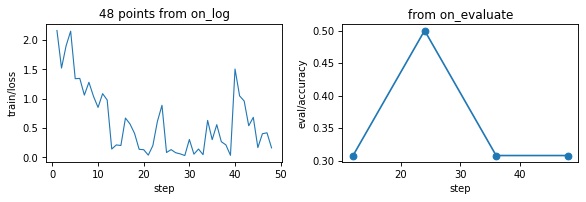

In [13]:
import matplotlib.pyplot as plt

plt.rcParams.update({"figure.dpi": 80, "font.size": 9})


def read_points(project, run_id, key):
    files = sorted(
        (Path(os.environ["CVPILOT_STORE_DIR"]) / project / "metrics" / run_id).glob("*.parquet")
    )
    points = {}
    for file in files:
        table = pq.read_table(file).to_pydict()
        for k, s, v in zip(table["key"], table["step"], table["value"], strict=True):
            if k == key:
                points[s] = v
    return sorted(points), [points[s] for s in sorted(points)]


fig, (a, b) = plt.subplots(1, 2, figsize=(7.4, 2.6))
steps, loss = read_points("crops-hf", CLEAN_RUN, "train/loss")
a.plot(steps, loss, lw=1)
a.set(xlabel="step", ylabel="train/loss", title=f"{len(steps)} points from on_log")
steps, acc = read_points("crops-hf", CLEAN_RUN, "eval/accuracy")
b.plot(steps, acc, marker="o")
b.set(xlabel="step", ylabel="eval/accuracy", title="from on_evaluate")
plt.tight_layout()
plt.show()

**What this shows.** The two curves the hook recorded: the training loss at every step (`on_log`) and the validation accuracy at every epoch end (`on_evaluate`).

## 5. Alerts: configuration, channels and a local listener

The configuration is a small JSON file: which channels deliver, a rate limit, and a few rules with
thresholds. There is no code and no template language in it. Channel addresses and credentials never
go into the file: they come from environment variables, and only over https. For this notebook we
need a **local** listener, which is allowed only with the documented development setting
`CVPILOT_ENV=dev`. First the production behaviour, then the development one.

In [14]:
ALERTS_TRAIN = {
    "channels": ["webhook", "slack"],
    "rate_limit_s": 30,
    "rules": [
        {"rule": "nan_loss"},
        {"rule": "no_progress", "patience": 12, "min_delta": 0.02},
        {"rule": "run_failed"},
    ],
}
Path("alerts_train.json").write_text(json.dumps(ALERTS_TRAIN, indent=2) + "\n")
print(Path("alerts_train.json").read_text())

{
  "channels": [
    "webhook",
    "slack"
  ],
  "rate_limit_s": 30,
  "rules": [
    {
      "rule": "nan_loss"
    },
    {
      "rule": "no_progress",
      "patience": 12,
      "min_delta": 0.02
    },
    {
      "rule": "run_failed"
    }
  ]
}



**What this shows.** The whole alert configuration for the training runs, as printed above: its rules, its channels and the shortest time between two alerts of one rule. Unknown keys, a repeated rule or an out-of-range number are refused when it is loaded.

In [15]:
import threading
from http.server import BaseHTTPRequestHandler, ThreadingHTTPServer


class Listener:
    """A local HTTP listener for the demo: records every POST and answers in the chosen way."""

    def __init__(self, mode="ok"):
        self.mode, self.received, self.release = mode, [], threading.Event()
        outer = self

        class Handler(BaseHTTPRequestHandler):
            protocol_version = "HTTP/1.1"

            def log_message(self, *a):
                return

            def do_POST(self):
                body = self.rfile.read(int(self.headers.get("Content-Length", "0")))
                outer.received.append(
                    {
                        "path": self.path,
                        "body": json.loads(body),
                        "bearer": "authorization" in self.headers,
                    }
                )
                if outer.mode == "slow":  # never answers
                    outer.release.wait(120)
                    return
                if outer.mode == "redirect":
                    self.send_response(302)
                    self.send_header("Location", f"http://127.0.0.1:{outer.port}/elsewhere")
                else:
                    self.send_response(200)
                self.send_header("Content-Length", "0")
                self.send_header("Connection", "close")
                self.end_headers()

        self.server = ThreadingHTTPServer(("127.0.0.1", 0), Handler)
        self.server.daemon_threads = True
        self.port = self.server.server_address[1]
        threading.Thread(target=self.server.serve_forever, daemon=True).start()

    def url(self, path):
        return f"http://127.0.0.1:{self.port}{path}"


def closed_port():
    with socket.socket() as probe:
        probe.bind(("127.0.0.1", 0))
        return probe.getsockname()[1]


GOOD, SLOW, REDIRECTING = Listener("ok"), Listener("slow"), Listener("redirect")
DEAD_PORT = closed_port()
CHANNEL_ENV = {
    "CVPILOT_ALERT_WEBHOOK_URL": GOOD.url("/webhook"),
    "CVPILOT_ALERT_WEBHOOK_TOKEN": "demo-bearer-0123456789",
    "CVPILOT_ALERT_SLACK_URL": GOOD.url("/services/T000/B000/DEMOONLY"),
}


def show_received(listener, start=0):
    for item in listener.received[start:]:
        body = item["body"]
        print(f"  POST {item['path']}")
        for key in ("source", "rule", "project", "step", "text", "mrkdwn"):
            if key in body:
                print(f"    {key}: {body[key]}")
    return len(listener.received)


print("listeners on 127.0.0.1 (ports hidden); a closed port is also prepared")

listeners on 127.0.0.1 (ports hidden); a closed port is also prepared


**What this shows.** A tiny HTTP listener (it records what it gets) in three flavours: one that answers 200, one that never answers, one that redirects. A fourth address is a port nobody listens on. They stand in for real channels.

In [16]:
import urllib.parse

result = sh(
    "cvpilot alerts check alerts_train.json", keep=True, env={**CHANNEL_ENV, "CVPILOT_ENV": "prod"}
)

$ cvpilot alerts check alerts_train.json
config: ok (3 rules, rate limit 30 s)
rule nan_loss
rule no_progress (patience=12, min_delta=0.02)
rule run_failed
stderr: error: CVPILOT_ALERT_WEBHOOK_URL must be an https URL (CVPILOT_ENV=dev also allows http for a local server)
exit code: 2


**What this shows.** In production mode (`CVPILOT_ENV` is `prod`) `http://127.0.0.1...` is refused: exit code 2 and a message that names the variable but never prints its value. Alerts go over https only.

In [17]:
os.environ.update(CHANNEL_ENV)
os.environ["CVPILOT_ENV"] = "dev"  # the documented development setting: http to a local listener
sh("cvpilot alerts check alerts_train.json")

$ cvpilot alerts check alerts_train.json
config: ok (3 rules, rate limit 30 s)
rule nan_loss
rule no_progress (patience=12, min_delta=0.02)
rule run_failed
channel webhook: ready
channel slack: ready
nothing was sent
log[WARNING] insecure_dev_mode channel=webhook reason=http to loopback addresses allowed
log[WARNING] insecure_dev_mode channel=slack reason=http to loopback addresses allowed
exit code: 0


**What this shows.** With `CVPILOT_ENV=dev` both channels can be built from the environment, so the check passes and prints the rules and `channel webhook: ready`. It sent nothing (`nothing was sent`): the listener has received zero requests so far.

In [18]:
print("requests received by the listener so far:", len(GOOD.received))

requests received by the listener so far: 0


**What this shows.** Zero: checking a configuration never sends.

## 6. An injected NaN loss and a loss plateau, in the real training

In [19]:
before = len(GOOD.received)
with timed("NaN run"):
    nan = sh(
        f"python train_hf.py --project crops-hf-nan --epochs 3 --inject nan --inject-step {INJECT_STEP} "
        "--alerts alerts_train.json",
        keep=True,
        log_lines=40,
        timeout=1800,
    )
NAN_RESULT = json.loads(next(ln for ln in nan.out.splitlines() if ln.startswith("RESULT "))[7:])
NAN_RUN = NAN_RESULT["run_id"]
time.sleep(1.0)
print("\nmessages the listener received (Trainer settings left at their defaults):")
n_after_nan = show_received(GOOD, before)

$ python train_hf.py --project crops-hf-nan --epochs 3 --inject nan --inject-step 8 --alerts alerts_train.json
RESULT {"run_id": "01M54W9ANN9KAE5K8KG8M7CEAK", "steps": 36, "train_runtime_s": 7.379, "mean_step_ms": 204.97, "train_call_wall_s": 7.537, "val_accuracy_per_epoch": [0.077, 0.077,  ...
stderr: W1017 20:09:47.549000 92232 torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.
log[WARNING] insecure_dev_mode channel=webhook reason=http to loopback addresses allowed
log[WARNING] insecure_dev_mode channel=slack reason=http to loopback addresses allowed
log[INFO] run_started run_id=01M54W9ANN9KAE5K8KG8M7CEAK project=crops-hf-nan status=running task=classification parent_run_id=None
log[INFO] hook_attached hook=hf framework=transformers==5.20.1 extra=hf license_notice=None
log[INFO] alert_fired run_id=01M54W9ANN9KAE5K8KG8M7CEAK rule=nan_loss step=12 project=crops-hf-nan
log[INFO] alert_delivered channel=webhook rule=nan_loss r


messages the listener received (Trainer settings left at their defaults):
  POST /webhook
    source: cvpilot
    rule: nan_loss
    project: crops-hf-nan
    step: 12
    text: [crops-hf-nan] Loss eval/loss is NaN at step 12 (run 01M54W9ANN9KAE5K8KG8M7CEAK).
  POST /services/T000/B000/DEMOONLY
    text: [crops-hf-nan] Loss eval/loss is NaN at step 12 (run 01M54W9ANN9KAE5K8KG8M7CEAK).
    mrkdwn: False
  POST /services/T000/B000/DEMOONLY
    text: [crops-hf-nan] Loss train/loss has not improved for 12 logged values (best 0, step 20) (run 01M54W9ANN9KAE5K8KG8M7CEAK).
    mrkdwn: False
  POST /webhook
    source: cvpilot
    rule: no_progress
    project: crops-hf-nan
    step: 20
    text: [crops-hf-nan] Loss train/loss has not improved for 12 logged values (best 0, step 20) (run 01M54W9ANN9KAE5K8KG8M7CEAK).


**What this shows.** The real loss was multiplied by NaN at step 8 and, as in real life, the NaN spread into the model weights. With the `Trainer`'s *default* settings, though, the first alert is not about the training loss: the `Trainer` has a setting (`logging_nan_inf_filter`, on by default) that replaces a NaN training loss with the average of the earlier losses since the last log (zero when it logs every step) **before any callback sees it**, so CV-Pilot could not see the NaN at the step where it happened. The alert printed above came later, from the evaluation loss at the end of the epoch, which the `Trainer` does not filter. If you want the training loss itself watched, turn that setting off, as the next cell does.

In [20]:
before = len(GOOD.received)
with timed("NaN run, Trainer NaN filter off"):
    raw = sh(
        f"python train_hf.py --project crops-hf-nan-raw --epochs 3 --inject nan "
        f"--inject-step {INJECT_STEP} --keep-nan --alerts alerts_train.json",
        keep=True,
        log_lines=40,
        timeout=1800,
    )
RAW_RESULT = json.loads(next(ln for ln in raw.out.splitlines() if ln.startswith("RESULT "))[7:])
NAN_RAW_RUN = RAW_RESULT["run_id"]
time.sleep(1.0)
print("\nmessages the listener received (logging_nan_inf_filter switched off):")
show_received(GOOD, before)

$ python train_hf.py --project crops-hf-nan-raw --epochs 3 --inject nan --inject-step 8 --keep-nan --alerts alerts_train.json
RESULT {"run_id": "01M54W9P0ZQM4MC35CRY6FZMZ9", "steps": 36, "train_runtime_s": 7.381, "mean_step_ms": 205.04, "train_call_wall_s": 7.547, "val_accuracy_per_epoch": [0.077, 0.077,  ...
stderr: W1017 20:09:59.157000 92317 torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.
log[WARNING] insecure_dev_mode channel=webhook reason=http to loopback addresses allowed
log[WARNING] insecure_dev_mode channel=slack reason=http to loopback addresses allowed
log[INFO] run_started run_id=01M54W9P0ZQM4MC35CRY6FZMZ9 project=crops-hf-nan-raw status=running task=classification parent_run_id=None
log[INFO] hook_attached hook=hf framework=transformers==5.20.1 extra=hf license_notice=None
log[INFO] alert_fired run_id=01M54W9P0ZQM4MC35CRY6FZMZ9 rule=nan_loss step=8 project=crops-hf-nan-raw
log[INFO] alert_delivered channel=w


messages the listener received (logging_nan_inf_filter switched off):
  POST /webhook
    source: cvpilot
    rule: nan_loss
    project: crops-hf-nan-raw
    step: 8
    text: [crops-hf-nan-raw] Loss train/loss is NaN at step 8 (run 01M54W9P0ZQM4MC35CRY6FZMZ9).
  POST /services/T000/B000/DEMOONLY
    text: [crops-hf-nan-raw] Loss train/loss is NaN at step 8 (run 01M54W9P0ZQM4MC35CRY6FZMZ9).
    mrkdwn: False


6

In [21]:
def alert_step(project, rule):
    steps = sorted(
        {
            m["body"]["step"]
            for m in GOOD.received
            if m["body"].get("rule") == rule and m["body"].get("project") == project
        }
    )
    return steps[0] if steps else None


for project, run_id, label in (
    ("crops-hf-nan", NAN_RUN, "Trainer defaults"),
    ("crops-hf-nan-raw", NAN_RAW_RUN, "NaN filter off"),
):
    steps, loss = read_points(project, run_id, "train/loss")
    at = dict(zip(steps, loss, strict=True))
    print(
        f"{label:17s} train/loss recorded at step {INJECT_STEP}: {at.get(INJECT_STEP)}   "
        f"first nan_loss alert at step {alert_step(project, 'nan_loss')}"
    )
default_step, raw_step = (
    alert_step("crops-hf-nan", "nan_loss"),
    alert_step("crops-hf-nan-raw", "nan_loss"),
)
print(f"the alert came {default_step - raw_step} steps earlier with the filter off")

Trainer defaults  train/loss recorded at step 8: 0.0   first nan_loss alert at step 12
NaN filter off    train/loss recorded at step 8: nan   first nan_loss alert at step 8
the alert came 4 steps earlier with the filter off


**What this shows.** With the filter off the NaN training loss reaches CV-Pilot at the step where it happened and the alert names `train/loss`; the numbers printed above (computed from the stored points and the messages the listener received) give the loss value that was recorded at the injection step in each run and how many steps earlier the alert came. Further NaN values were not sent again: the log of the run shows `alert_suppressed`.

In [22]:
before = len(GOOD.received)
with timed("plateau run"):
    plateau = sh(
        "python train_hf.py --project crops-hf-plateau --epochs 3 --lr 0 "
        "--alerts alerts_train.json",
        keep=True,
        log_lines=40,
        timeout=1800,
    )
PLATEAU_RESULT = json.loads(
    next(ln for ln in plateau.out.splitlines() if ln.startswith("RESULT "))[7:]
)
PLATEAU_RUN = PLATEAU_RESULT["run_id"]
time.sleep(1.0)
print("\nmessages the listener received:")
n_after_plateau = show_received(GOOD, before)

$ python train_hf.py --project crops-hf-plateau --epochs 3 --lr 0 --alerts alerts_train.json
RESULT {"run_id": "01M54WA1B2169MAT2R0SKGQTK7", "steps": 36, "train_runtime_s": 7.59, "mean_step_ms": 210.84, "train_call_wall_s": 7.757, "val_accuracy_per_epoch": [0.115, 0.077, 0 ...
stderr: W1017 20:10:10.738000 92530 torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.
log[WARNING] insecure_dev_mode channel=webhook reason=http to loopback addresses allowed
log[WARNING] insecure_dev_mode channel=slack reason=http to loopback addresses allowed
log[INFO] run_started run_id=01M54WA1B2169MAT2R0SKGQTK7 project=crops-hf-plateau status=running task=classification parent_run_id=None
log[INFO] hook_attached hook=hf framework=transformers==5.20.1 extra=hf license_notice=None
log[INFO] hook_checkpoint_saved hook=hf step=12
log[INFO] hook_checkpoint_saved hook=hf step=24
log[INFO] alert_fired run_id=01M54WA1B2169MAT2R0SKGQTK7 rule=no_progress s


messages the listener received:
  POST /webhook
    source: cvpilot
    rule: no_progress
    project: crops-hf-plateau
    step: 29
    text: [crops-hf-plateau] Loss train/loss has not improved for 12 logged values (best 1.991, step 29) (run 01M54WA1B2169MAT2R0SKGQTK7).
  POST /services/T000/B000/DEMOONLY
    text: [crops-hf-plateau] Loss train/loss has not improved for 12 logged values (best 1.991, step 29) (run 01M54WA1B2169MAT2R0SKGQTK7).
    mrkdwn: False


**What this shows.** With the learning rate at zero the model cannot improve, so the loss only wobbles. After the number of logged values without a new lowest loss that the configuration asks for (it is in the message text) the `no_progress` rule fired; the log shows how many alerts were sent and delivered.

In [23]:
sent_before = len(GOOD.received)
sh(
    f"cvpilot alerts check alerts_train.json --project crops-hf-nan-raw --run {NAN_RAW_RUN}",
    lines=20,
)
print("requests received by the listener during the dry run:", len(GOOD.received) - sent_before)

$ cvpilot alerts check alerts_train.json --project crops-hf-nan-raw --run 01M54W9P0ZQM4MC35CRY6FZMZ9
config: ok (3 rules, rate limit 30 s)
rule nan_loss
rule no_progress (patience=12, min_delta=0.02)
rule run_failed
channel webhook: ready
channel slack: ready
replay: run 01M54W9P0ZQM4MC35CRY6FZMZ9 (project crops-hf-nan-raw): 167 points, 0 evaluation snapshots, status finished
would fire: nan_loss at step 8: [crops-hf-nan-raw] Loss train/loss is NaN at step 8 (run 01M54W9P0ZQM4MC35CRY6FZMZ9).
would suppress: 28 (rate limit or per-run cap)
nothing was sent
log[WARNING] insecure_dev_mode channel=webhook reason=http to loopback addresses allowed
log[WARNING] insecure_dev_mode channel=slack reason=http to loopback addresses allowed
exit code: 0
requests received by the listener during the dry run: 0


**What this shows.** `cvpilot alerts check ... --run RUN` replays the recorded NaN run against the configuration and prints what would fire, with the same message the real run sent. The listener received nothing during the dry run.

In [24]:
from cvpilot.core.schema import Alert
from cvpilot.logging import configure_logging
from cvpilot.notify.telegram import TelegramChannel
from cvpilot.settings import load_settings

configure_logging("notebook", load_settings())  # plain JSON log lines, quiet at WARNING
os.environ["CVPILOT_ALERT_TELEGRAM_TOKEN"] = "123456789:AAH-demo_only-0123456789abcdefghijkl"  # noqa: S105
os.environ["CVPILOT_ALERT_TELEGRAM_CHAT"] = "-1001234567890"
telegram = TelegramChannel(allow_insecure=True, base_url=GOOD.url(""))  # base_url: development only
start = len(GOOD.received)
telegram.send(
    [
        Alert(
            rule="nan_loss",
            project="crops-hf-nan-raw",
            run_id=NAN_RAW_RUN,
            step=INJECT_STEP,
            text=f"[crops-hf-nan-raw] Loss train/loss is NaN at step {INJECT_STEP} (run {NAN_RAW_RUN}).",
        )
    ]
)
item = GOOD.received[start]
print(
    "path shape:",
    item["path"].split("/")[1].split(":")[0] + ":<bot token>/" + item["path"].rsplit("/", 1)[1],
)
print({k: v for k, v in item["body"].items()})

{"logger": "cvpilot.notify", "channel": "telegram", "reason": "http to loopback addresses allowed", "service": "notebook", "env": "dev", "request_id": "bd48d4e2-b441-4e48-b821-362c0f94a975", "level": "WARNING", "@timestamp": "2026-10-17T12:10:20.960803Z", "message": "insecure_dev_mode"}


path shape: bot123456789:<bot token>/sendMessage
{'chat_id': -1001234567890, 'text': '[crops-hf-nan-raw] Loss train/loss is NaN at step 8 (run 01M54W9P0ZQM4MC35CRY6FZMZ9).', 'disable_web_page_preview': True}


**What this shows.** The Telegram channel sends plain text (no `parse_mode`, so nothing in it is interpreted as formatting) to the bot API path. The bot token is part of that path by Telegram's design, so it is kept inside the channel object and never printed or logged; the printed path hides it.

## 7. A real regression: YOLO11n at 640 px as baseline, 160 px as the candidate

In [25]:
import cvpilot
from cvpilot.eval import AnnotationTable, ImageTable, PredictionTable


def to_tables(gt_table, pred_table):
    """Wrap the two Parquet tables in the objects `Run.log_eval` takes."""
    g = gt_table.to_pydict()
    sizes = {i: (w, h) for i, w, h in zip(g["image_id"], g["width"], g["height"], strict=True)}
    ids = sorted(sizes)
    images = ImageTable.from_columns(
        image_id=ids, width=[sizes[i][0] for i in ids], height=[sizes[i][1] for i in ids]
    )
    keep = [i for i, c in enumerate(g["cls"]) if c is not None]
    annotations = AnnotationTable.from_columns(
        image_id=[g["image_id"][i] for i in keep],
        class_id=[g["cls"][i] for i in keep],
        boxes=np.array([[g[k][i] for k in ("x1", "y1", "x2", "y2")] for i in keep]),
        images=images,
    )
    p = pred_table.to_pydict()
    predictions = PredictionTable.from_columns(
        image_id=p["image_id"],
        class_id=p["cls"],
        score=p["score"],
        boxes=np.column_stack([p[k] for k in ("x1", "y1", "x2", "y2")]),
    )
    return predictions, annotations

In [26]:
preds640, secs640, cached640 = detect(640, use_cache=True)
preds160, secs160, cached160 = detect(160, use_cache=True)
print("detections at 640 px:", len(preds640), "| at 160 px:", len(preds160))
os.environ["CVPILOT_PROJECT"] = "coco128-yolo"
run = cvpilot.init(
    "coco128-yolo",
    task="detection",
    name="yolo11n-640-baseline",
    dataset_uri=COCO_ROOT,
    config={"model": "yolo11n", "imgsz": 640, "device": "cpu"},
)
snap = run.log_eval(*to_tables(gt, preds640), step=0, class_names=NAMES)
cvpilot.finish()
BASE_RUN = run.run_id
print(f"baseline run {BASE_RUN[:10]}...  mAP50-95 = {100 * snap.metrics['mAP50_95']:.2f}")
sh(f"cvpilot baseline set prod {BASE_RUN}")

detections at 640 px: 16017 | at 160 px: 7012


baseline run 01M54WAAY3...  mAP50-95 = 50.33


$ cvpilot baseline set prod 01M54WAAY3FSG28R0K81K2Q0A0
pinned prod: run 01M54WAAY3FSG28R0K81K2Q0A0 eval_set b720c966844f step 0
log[INFO] baseline_set project=coco128-yolo tag=prod run_id=01M54WAAY3FSG28R0K81K2Q0A0 eval_set_hash=b720c966844f83652fb422c7aac5587ae4a340258c5e step=0 replaced=False
exit code: 0


**What this shows.** The 640 px detections are scored and stored as an evaluation snapshot, and that run is pinned under the name `prod`, the model we trust.

In [27]:
ALERTS_EVAL = {
    "channels": ["webhook"],
    "rate_limit_s": 30,
    "rules": [{"rule": "eval_regression", "baseline": "tag:prod", "max_drop": {"mAP50_95": 0.5}}],
}
Path("alerts_eval.json").write_text(json.dumps(ALERTS_EVAL, indent=2) + "\n")
print(Path("alerts_eval.json").read_text())


def candidate(name, preds, size):
    run = cvpilot.init(
        "coco128-yolo",
        task="detection",
        name=name,
        alerts="alerts_eval.json",
        config={"model": "yolo11n", "imgsz": size, "device": "cpu"},
    )
    snapshot = run.log_eval(*to_tables(gt, preds), step=0, class_names=NAMES)
    cvpilot.finish()
    return run.run_id, snapshot.metrics["mAP50_95"]


start = len(GOOD.received)
equal_run, equal_map = candidate("yolo11n-640-same", preds640, 640)
time.sleep(0.5)
print(
    f"equal candidate: mAP50-95 = {100 * equal_map:.2f}; alerts received: {len(GOOD.received) - start}"
)
bad_start = len(GOOD.received)
bad_run, bad_map = candidate("yolo11n-160", preds160, 160)
time.sleep(1.0)
print(
    f"degraded candidate: mAP50-95 = {100 * bad_map:.2f}; alerts received: {len(GOOD.received) - bad_start}"
)
show_received(GOOD, bad_start)

{"logger": "cvpilot.notify", "channel": "webhook", "reason": "http to loopback addresses allowed", "service": "notebook", "env": "dev", "request_id": "01M54WAAY3FSG28R0K81K2Q0A0:3", "level": "WARNING", "@timestamp": "2026-10-17T12:10:22.340523Z", "message": "insecure_dev_mode"}


{
  "channels": [
    "webhook"
  ],
  "rate_limit_s": 30,
  "rules": [
    {
      "rule": "eval_regression",
      "baseline": "tag:prod",
      "max_drop": {
        "mAP50_95": 0.5
      }
    }
  ]
}



{"logger": "cvpilot.notify", "channel": "webhook", "reason": "http to loopback addresses allowed", "service": "notebook", "env": "dev", "request_id": "01M54WAC84FM5T8P83JBRKY2R3:4", "level": "WARNING", "@timestamp": "2026-10-17T12:10:23.833291Z", "message": "insecure_dev_mode"}


equal candidate: mAP50-95 = 50.33; alerts received: 0


degraded candidate: mAP50-95 = 18.19; alerts received: 1
  POST /webhook
    source: cvpilot
    rule: eval_regression
    project: coco128-yolo
    step: 0
    text: [coco128-yolo] Evaluation at step 0 is worse than baseline tag:prod: headline_drop on mAP50_95 (32.1 points below) (run 01M54WADPS1974X8ZN16YJN8RY).


10

**What this shows.** The configuration holds one rule: fail if mAP50-95 falls by more than 0.5 points against `prod`. The equal candidate (same detections) sends no alert. The same model fed 160 px pictures scores much lower, so `log_eval` ran the real baseline comparison, and an `eval_regression` alert with the worst violation arrived. The number in the message is the same one `cvpilot gate` would print.

In [28]:
sh(
    f"cvpilot gate {bad_run} --baseline tag:prod --max-drop mAP50_95=0.5 --min-images 30",
    lines=6,
    log_lines=2,
)
sh(f"cvpilot alerts check alerts_eval.json --project coco128-yolo --run {bad_run}", lines=12)

$ cvpilot gate 01M54WADPS1974X8ZN16YJN8RY --baseline tag:prod --max-drop mAP50_95=0.5 --min-images 30
gate: FAIL (1 violations, worst: [headline_drop] mAP50_95) run 01M54WADPS1974X8ZN16YJN8RY step 0 vs baseline tag:prod
  - [headline_drop] mAP50_95: mAP50_95 dropped 32.15 points (limit 0.5)
log[ERROR] gate_failed run_id=01M54WADPS1974X8ZN16YJN8RY baseline_tag=prod n_violations=1 worst_metric=mAP50_95 worst_kind=headline_drop worst_delta=-32.147019628
exit code: 1


$ cvpilot alerts check alerts_eval.json --project coco128-yolo --run 01M54WADPS1974X8ZN16YJN8RY
config: ok (1 rules, rate limit 30 s)
rule eval_regression (baseline=tag:prod, max_drop={'mAP50_95': 0.5})
channel webhook: ready
replay: run 01M54WADPS1974X8ZN16YJN8RY (project coco128-yolo): 0 points, 1 evaluation snapshots, status finished
note: evaluation snapshots carry no recording time; each is replayed one rate-limit window after the previous event
would fire: eval_regression at step 0: [coco128-yolo] Evaluation at step 0 is worse than baseline tag:prod: headline_drop on mAP50_95 (32.1 points below) (run 01M54WADPS1974X8ZN16Y ...
nothing was sent
log[WARNING] insecure_dev_mode channel=webhook reason=http to loopback addresses allowed
exit code: 0


**What this shows.** `cvpilot gate` (the CI check) reaches the same verdict on the same run, and the dry run of the alert configuration lists the same message.

## 8. Do dead channels slow or crash training?

Two measurements, with different strengths.

**First, a coarse one on a real `Trainer` run:** the same fine-tuning is repeated under five
conditions, three times each. In every alert condition alerts really fire during training (the
learning rate is zero and the plateau rule has a huge threshold, so it fires about once a second).
Mean step time is the `Trainer`'s own `train_runtime` divided by its step count. The order of the
conditions is rotated in every repetition, so no condition is always run first (a laptop speeds up
and slows down over the minutes this takes). The spread of the no-alert runs, printed below, says how
small a difference this measurement could ever show.

**Then a precise one on a single `log()` call**, while alerts really fire, in this process.

In [29]:
ALERTS_BENCH = {
    "channels": ["webhook"],
    "rate_limit_s": 1,
    "rules": [
        {"rule": "nan_loss"},
        {"rule": "no_progress", "patience": 2, "min_delta": 1000},
        {"rule": "run_failed"},
    ],
}
Path("alerts_bench.json").write_text(json.dumps(ALERTS_BENCH, indent=2) + "\n")
CONDITIONS = [
    ("no alerts at all", None, None),
    ("healthy channel", GOOD.url("/hook"), GOOD),
    ("closed port", f"http://127.0.0.1:{DEAD_PORT}/hook", None),
    ("never answers", SLOW.url("/hook"), SLOW),
    ("redirects", REDIRECTING.url("/hook"), REDIRECTING),
]
ROWS = []


def count_events(events, name):
    return sum(e.get("message") == name for e in events)


with timed("step-time measurement (15 training runs)"):
    for repetition in (1, 2, 3):
        shift = 2 * (repetition - 1)  # a different order in every repetition
        for position, (label, url, listener) in enumerate(
            CONDITIONS[shift:] + CONDITIONS[:shift], 1
        ):
            env = {"CVPILOT_ENV": "dev"}
            args = "--lr 0 --epochs 6"
            if url is not None:
                env["CVPILOT_ALERT_WEBHOOK_URL"] = url
                args += " --alerts alerts_bench.json"
            n0 = len(listener.received) if listener else 0
            res = sh(
                f"python train_hf.py --project crops-hf-bench {args}",
                quiet=True,
                env=env,
                timeout=1800,
            )
            if res.code != 0:
                raise RuntimeError(f"the training process failed under '{label}' (exit {res.code})")
            summary = json.loads(
                next(ln for ln in res.out.splitlines() if ln.startswith("RESULT "))[7:]
            )
            events = [json.loads(ln) for ln in res.err.splitlines() if ln.startswith("{")]
            ROWS.append(
                dict(
                    label=label,
                    rep=repetition,
                    steps=summary["steps"],
                    mean_step_ms=summary["mean_step_ms"],
                    train_call_s=summary["train_call_wall_s"],
                    fired=count_events(events, "alert_fired"),
                    delivered=count_events(events, "alert_delivered"),
                    delivery_failed=count_events(events, "alert_delivery_failed"),
                    received=(len(listener.received) - n0) if listener else 0,
                    pos=position,
                    exit_code=res.code,
                )
            )
print(
    f"{'condition':18s} {'run':>3s} {'steps':>5s} {'ms/step':>8s} {'train() s':>9s} {'fired':>5s} "
    f"{'delivered':>9s} {'failed':>6s} {'listener got':>12s} {'order':>5s}"
)
for r in ROWS:
    print(
        f"{r['label']:18s} {r['rep']:3d} {r['steps']:5d} {r['mean_step_ms']:8.1f} {r['train_call_s']:9.2f} "
        f"{r['fired']:5d} {r['delivered']:9d} {r['delivery_failed']:6d} {r['received']:12d} {r['pos']:5d}"
    )
print()
print("CHECK: every run exited 0:", all(r["exit_code"] == 0 for r in ROWS))
print("CHECK: every run took the same number of steps:", len({r["steps"] for r in ROWS}) == 1)
print(
    "CHECK: alerts fired in every alert condition:",
    all(r["fired"] >= 1 for r in ROWS if r["label"] != "no alerts at all"),
)
print(
    "CHECK: nothing was delivered through a dead channel:",
    all(
        r["delivered"] == 0
        for r in ROWS
        if r["label"] in ("closed port", "never answers", "redirects")
    ),
)
print(
    "CHECK: the redirecting listener received exactly what was fired, none at the redirect target:",
    all(r["received"] == r["fired"] for r in ROWS if r["label"] == "redirects"),
    all(i["path"] != "/elsewhere" for i in REDIRECTING.received),
)

[step-time measurement (15 training runs): 311.7 s]
condition          run steps  ms/step train() s fired delivered failed listener got order
no alerts at all     1    72    203.7     14.78     0         0      0            0     1
healthy channel      1    72    208.9     15.20    12        12      0           12     2
closed port          1    72    207.9     15.14    12         0      1            0     3
never answers        1    72    210.1     27.25    12         0      1            5     4
redirects            1    72    205.1     14.91    12         0      1           12     5
closed port          2    72    201.6     14.68    12         0      1            0     1
never answers        2    72    203.5     26.77    12         0      1            5     2
redirects            2    72    203.6     14.81    12         0      1           12     3
no alerts at all     2    72    208.8     15.14     0         0      0            0     4
healthy channel      2    72    210.3     15.27 

**What this shows.** Each row is one real training run; the `CHECK` lines are computed from the rows. They show that every run finished normally with the same number of steps, that alerts really fired in every alert condition (so the dead channels were exercised, not idle), that nothing reached a dead channel's destination, and that the redirecting endpoint received exactly the requests that were sent and no request at the address it redirected to. The `order` column shows the rotated order of the conditions.

condition          mean ms/step            range  vs no alerts
no alerts at all          205.5   203.7-  208.8         +0.0%
healthy channel           209.3   208.8-  210.3         +1.9%
closed port               206.5   201.6-  209.9         +0.5%
never answers             206.2   203.5-  210.1         +0.4%
redirects                 205.5   203.6-  207.8         -0.0%

no alerts at all   whole train() call  14.91 s   (+0.00 s vs no alerts)
healthy channel    whole train() call  15.22 s   (+0.31 s vs no alerts)
closed port        whole train() call  15.02 s   (+0.11 s vs no alerts)
never answers      whole train() call  26.97 s   (+12.07 s vs no alerts)
redirects          whole train() call  14.93 s   (+0.03 s vs no alerts)


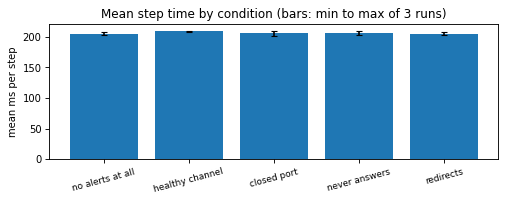


VERDICT: the slowest alert condition (healthy channel) averaged 209.3 ms per step against 205.5 ms with no alerts (+1.9%). The three no-alert runs alone differ by 2.5% between fastest and slowest.
VERDICT: this measurement cannot resolve a difference smaller than about 2%, so it can only rule out a large slowdown. No slowdown larger than that noise is visible.
VERDICT: the cost of one log() call, measured next, carries the per-call claim.


In [30]:
import statistics

means = {}
for label, *_ in CONDITIONS:
    vals = [r["mean_step_ms"] for r in ROWS if r["label"] == label]
    means[label] = (statistics.mean(vals), min(vals), max(vals))
base = means["no alerts at all"][0]
print(f"{'condition':18s} {'mean ms/step':>12s} {'range':>16s} {'vs no alerts':>13s}")
for label, (m, lo, hi) in means.items():
    print(f"{label:18s} {m:12.1f} {lo:7.1f}-{hi:7.1f} {100 * (m - base) / base:+12.1f}%")
walls = {
    lab: statistics.mean(r["train_call_s"] for r in ROWS if r["label"] == lab)
    for lab, *_ in CONDITIONS
}
print()
for label, wall in walls.items():
    print(
        f"{label:18s} whole train() call {wall:6.2f} s   ({wall - walls['no alerts at all']:+.2f} s vs no alerts)"
    )
fig, ax = plt.subplots(figsize=(6.4, 2.6))
ax.bar(
    range(len(means)),
    [v[0] for v in means.values()],
    yerr=[[v[0] - v[1] for v in means.values()], [v[2] - v[0] for v in means.values()]],
    capsize=3,
)
ax.set_xticks(range(len(means)), list(means), rotation=15, fontsize=8)
ax.set(ylabel="mean ms per step", title="Mean step time by condition (bars: min to max of 3 runs)")
plt.tight_layout()
plt.show()
spread = 100 * (means["no alerts at all"][2] - means["no alerts at all"][1]) / base
worst_label, worst = max(
    ((k, v[0]) for k, v in means.items() if k != "no alerts at all"), key=lambda kv: kv[1]
)
slowdown = 100 * (worst - base) / base
print()
print(
    f"VERDICT: the slowest alert condition ({worst_label}) averaged {worst:.1f} ms per step against {base:.1f} ms with no alerts "
    f"({slowdown:+.1f}%). The three no-alert runs alone differ by {spread:.1f}% between fastest and slowest."
)
print(
    f"VERDICT: this measurement cannot resolve a difference smaller than about {spread:.0f}%, so it can only rule out a large slowdown. "
    + (
        "A slowdown larger than that noise IS visible."
        if slowdown > spread
        else "No slowdown larger than that noise is visible."
    )
)
print("VERDICT: the cost of one log() call, measured next, carries the per-call claim.")

**What this shows.** The table and the bars compare the mean time of one training step in the five conditions. The sentences printed under the chart are computed from the table: they say how far the slowest alert condition is from the no-alert baseline, compare that with how much the no-alert runs differ from each other, and say what the measurement can and cannot rule out. The second table shows the whole `train()` call, which includes the wait at the end of the run: a never-answering endpoint can make that wait longer than the other conditions, but the wait comes after the last training step.

In [31]:
# the precise measurement: one log() call, while alerts really fire and the channel is dead
import cvpilot
from cvpilot.runs import forwarding

os.environ["CVPILOT_ENV"] = "dev"


def percentile(values, q):
    ordered = sorted(values)
    return ordered[min(len(ordered) - 1, int(len(ordered) * q))]


LATENCY = {}
for label, url, _ in CONDITIONS[2:]:  # unpaced: 5000 calls, a NaN loss every time
    os.environ["CVPILOT_ALERT_WEBHOOK_URL"] = url
    run = cvpilot.init("latency", task="classification", alerts="alerts_bench.json")
    times = []
    for step in range(5000):
        t0 = time.perf_counter()
        run.log({"train/loss": float("nan")}, step=step)
        times.append((time.perf_counter() - t0) * 1e6)
    queued = run.handle._alerts.stats.queued
    t0 = time.perf_counter()
    cvpilot.finish("failed")
    finish_s = time.perf_counter() - t0
    if queued < 1:
        raise RuntimeError(
            f"no alert was queued under '{label}': the measurement would be of the idle path"
        )
    LATENCY[label] = (percentile(times, 0.5), percentile(times, 0.99), max(times), queued, finish_s)
print(
    f"{'dead channel':16s} {'log() p50':>10s} {'p99':>9s} {'max':>10s} {'alerts queued':>14s} {'finish() waited':>16s}"
)
for label, (p50, p99, mx, queued, fin) in LATENCY.items():
    print(f"{label:16s} {p50:8.1f} us {p99:7.1f} us {mx:8.0f} us {queued:14d} {fin:14.2f} s")

{"logger": "cvpilot.notify", "channel": "webhook", "reason": "http to loopback addresses allowed", "service": "notebook", "env": "dev", "request_id": "01M54WADPS1974X8ZN16YJN8RY:5", "level": "WARNING", "@timestamp": "2026-10-17T12:15:38.306558Z", "message": "insecure_dev_mode"}


{"logger": "cvpilot.notify", "channel": "webhook", "run_id": "01M54WM0T2AY1WMCDFKHV2A45T", "n_alerts": 1, "reason": "exception", "error_type": "ConnectionRefusedError", "service": "notebook", "env": "dev", "request_id": "01M54WADPS1974X8ZN16YJN8RY:5", "level": "WARNING", "@timestamp": "2026-10-17T12:15:39.008034Z", "message": "alert_delivery_failed"}


{"logger": "cvpilot.notify", "channel": "webhook", "run_id": "01M54WM0T2AY1WMCDFKHV2A45T", "failed_calls": 2, "dropped_batches": 0, "dropped_alerts": 0, "failed_alerts": 2, "adapter_dropped_alerts": 0, "disabled_reason": null, "abandoned": false, "service": "notebook", "env": "dev", "request_id": "01M54WM0T2AY1WMCDFKHV2A45T:6", "level": "WARNING", "@timestamp": "2026-10-17T12:15:39.579171Z", "message": "alert_delivery_summary"}


{"logger": "cvpilot.notify", "channel": "webhook", "reason": "http to loopback addresses allowed", "service": "notebook", "env": "dev", "request_id": "01M54WM0T2AY1WMCDFKHV2A45T:7", "level": "WARNING", "@timestamp": "2026-10-17T12:15:39.590169Z", "message": "insecure_dev_mode"}


{"logger": "cvpilot.notify", "channel": "webhook", "run_id": "01M54WM226C7RKEWVPYSX1Q27N", "n_alerts": 1, "reason": "exception", "error_type": "TimeoutError", "service": "notebook", "env": "dev", "request_id": "01M54WM0T2AY1WMCDFKHV2A45T:7", "level": "WARNING", "@timestamp": "2026-10-17T12:15:50.310773Z", "message": "alert_delivery_failed"}


{"logger": "cvpilot.notify", "channel": "webhook", "run_id": "01M54WM226C7RKEWVPYSX1Q27N", "failed_calls": 1, "dropped_batches": 0, "dropped_alerts": 0, "failed_alerts": 1, "adapter_dropped_alerts": 0, "disabled_reason": null, "abandoned": true, "service": "notebook", "env": "dev", "request_id": "01M54WM226C7RKEWVPYSX1Q27N:6", "level": "WARNING", "@timestamp": "2026-10-17T12:15:51.829535Z", "message": "alert_delivery_summary"}


{"logger": "cvpilot.notify", "channel": "webhook", "reason": "http to loopback addresses allowed", "service": "notebook", "env": "dev", "request_id": "01M54WM226C7RKEWVPYSX1Q27N:7", "level": "WARNING", "@timestamp": "2026-10-17T12:15:51.837315Z", "message": "insecure_dev_mode"}


{"logger": "cvpilot.notify", "channel": "webhook", "run_id": "01M54WME0XHJXXZ9Y2G4HX3H33", "n_alerts": 1, "reason": "exception", "error_type": "RedirectRefused", "service": "notebook", "env": "dev", "request_id": "01M54WM226C7RKEWVPYSX1Q27N:7", "level": "WARNING", "@timestamp": "2026-10-17T12:15:52.040469Z", "message": "alert_delivery_failed"}


{"logger": "cvpilot.notify", "channel": "webhook", "run_id": "01M54WME0XHJXXZ9Y2G4HX3H33", "failed_calls": 2, "dropped_batches": 0, "dropped_alerts": 0, "failed_alerts": 2, "adapter_dropped_alerts": 0, "disabled_reason": null, "abandoned": false, "service": "notebook", "env": "dev", "request_id": "01M54WME0XHJXXZ9Y2G4HX3H33:6", "level": "WARNING", "@timestamp": "2026-10-17T12:15:52.099102Z", "message": "alert_delivery_summary"}


dead channel      log() p50       p99        max  alerts queued  finish() waited
closed port           5.8 us    12.1 us      600 us              1           1.09 s
never answers         5.7 us    11.4 us      320 us              1          12.02 s
redirects             5.5 us    10.2 us      278 us              1           0.06 s


**What this shows.** One `log()` call is timed 5000 times while every call carries a NaN loss and a dead channel is configured. The cell stops with an error if no alert was queued, so these numbers are for calls that really fired an alert: the median and 99th percentile cost of the call (microseconds), the slowest single call, how many alerts were queued, and how long `finish()` waited for the channel.

In [32]:
# the channel's queue saturated: calls paced so that alerts keep coming while one delivery never returns
os.environ["CVPILOT_ALERT_WEBHOOK_URL"] = SLOW.url("/hook")
run = cvpilot.init("latency", task="classification", alerts="alerts_bench.json")
worker = run.handle._notify._workers[0]
before, during = [], []
started = time.perf_counter()
step = 0
while time.perf_counter() - started < 26:
    t0 = time.perf_counter()
    run.log({"train/loss": float("nan")}, step=step)
    elapsed = (time.perf_counter() - t0) * 1e6
    (during if worker.stats.dropped_batches > 0 else before).append(elapsed)
    step += 1
    time.sleep(0.01)
dropped, queued = worker.stats.dropped_batches, run.handle._alerts.stats.queued
t0 = time.perf_counter()
cvpilot.finish("failed")
finish_s = time.perf_counter() - t0
if dropped < 1 or not during:
    raise RuntimeError("the channel queue never overflowed: the saturated case was not measured")
for label, values in (("before the queue overflowed", before), ("after it overflowed", during)):
    print(
        f"log() {label:28s}: {len(values):5d} calls, p50 {percentile(values, 0.5):7.1f} us, "
        f"p99 {percentile(values, 0.99):7.1f} us, max {max(values):8.0f} us"
    )
print(
    f"alerts queued {queued}, dropped because the queue was full or the call was stuck: {dropped}"
)
print(
    f"finish() waited {finish_s:.2f} s for the channel (its limit is {forwarding.NOTIFY_CLOSE_TIMEOUT_S:g} s)"
)

{"logger": "cvpilot.notify", "channel": "webhook", "reason": "http to loopback addresses allowed", "service": "notebook", "env": "dev", "request_id": "01M54WME0XHJXXZ9Y2G4HX3H33:7", "level": "WARNING", "@timestamp": "2026-10-17T12:15:52.107507Z", "message": "insecure_dev_mode"}


{"logger": "cvpilot.notify", "channel": "webhook", "run_id": "01M54WME9B35H1SXGQ1BFH89P2", "n_alerts": 1, "reason": "exception", "error_type": "TimeoutError", "service": "notebook", "env": "dev", "request_id": "01M54WME0XHJXXZ9Y2G4HX3H33:7", "level": "WARNING", "@timestamp": "2026-10-17T12:16:02.770763Z", "message": "alert_delivery_failed"}


{"logger": "cvpilot.notify", "channel": "webhook", "run_id": "01M54WME9B35H1SXGQ1BFH89P2", "failed_calls": 3, "dropped_batches": 3, "dropped_alerts": 3, "failed_alerts": 3, "adapter_dropped_alerts": 0, "disabled_reason": null, "abandoned": true, "service": "notebook", "env": "dev", "request_id": "01M54WME9B35H1SXGQ1BFH89P2:38", "level": "WARNING", "@timestamp": "2026-10-17T12:16:30.274710Z", "message": "alert_delivery_summary"}


log() before the queue overflowed :  1246 calls, p50    52.5 us, p99   718.5 us, max     6993 us
log() after it overflowed         :   653 calls, p50    46.2 us, p99   154.7 us, max     5538 us
alerts queued 20, dropped because the queue was full or the call was stuck: 3
finish() waited 12.02 s for the channel (its limit is 12 s)


**What this shows.** The endpoint never answers, so the first delivery is stuck and the later alerts pile up in the channel's small queue until it overflows (the cell stops with an error if that never happens). The two lines compare the cost of a `log()` call before and after the overflow: the call does not wait for the network in either case. The last lines show how many alerts were dropped and how long `finish()` waited, which is bounded by the limit printed with it.

## 9. What was recorded

In [33]:
sh("cvpilot runs list --project crops-hf-nan-raw")
sh("cvpilot runs list --project crops-hf-plateau")
print(
    {
        "clean run mean step ms": CLEAN_RESULT["mean_step_ms"],
        "NaN run": NAN_RESULT["mean_step_ms"],
        "plateau run": PLATEAU_RESULT["mean_step_ms"],
    }
)
print(
    "received by the healthy listener:",
    len(GOOD.received),
    "messages; by the redirecting one:",
    len(REDIRECTING.received),
)
print(
    "CHECK: nothing reached the address the redirects pointed at:",
    all(i["path"] != "/elsewhere" for i in REDIRECTING.received),
)
print("timings:", TIMINGS)
for listener in (SLOW,):
    listener.release.set()

$ cvpilot runs list --project crops-hf-nan-raw
RUN_ID                      STATUS     STARTED                    NAME
01M54W9P0ZQM4MC35CRY6FZMZ9  finished   2026-10-17T12:09:59.771034+00:00  transformers-2026-10-17
exit code: 0


$ cvpilot runs list --project crops-hf-plateau
RUN_ID                      STATUS     STARTED                    NAME
01M54WA1B2169MAT2R0SKGQTK7  finished   2026-10-17T12:10:11.361664+00:00  transformers-2026-10-17
exit code: 0
{'clean run mean step ms': 205.1, 'NaN run': 204.97, 'plateau run': 210.84}
received by the healthy listener: 46 messages; by the redirecting one: 38
CHECK: nothing reached the address the redirects pointed at: True
timings: {'import torch and ultralytics, load YOLO11n': 1.9, 'fine-tune ResNet-18, 4 epochs, CPU': 13.7, 'NaN run': 10.5, 'NaN run, Trainer NaN filter off': 10.6, 'plateau run': 10.8, 'step-time measurement (15 training runs)': 311.7}


**What this shows.** The other runs of the notebook are in the store like any run. The numbers of messages received are totals over the whole notebook, and the `CHECK` line is computed from what the redirecting listener received.

## What this notebook proved, and what it did not

*Proved on real data and a real model:* the Hugging Face `Trainer` hook records a real fine-tuning run; an injected NaN loss and a plateau produce alerts that arrive, once each, at local webhook and Slack-style listeners with the exact messages shown; a real regression found by the real baseline comparison alerts and an equal candidate does not; a closed port, an endpoint that never answers and a redirect never crash the training, are counted and logged once, and cost a `log()` call microseconds even with the channel's queue full (the step-time comparison is too noisy on a laptop to show anything below its own spread); `alerts check` replays a run and sends nothing; production mode refuses plain http.

*Not proved:* good thresholds for long GPU jobs, behaviour under many processes (only rank zero alerts), real Slack or Telegram delivery (no account was used; the payloads were checked at a local listener and in the unit tests), a hung process that logs nothing (it cannot be seen from inside the process), and false-alarm rates on real jobs. The classifier is tiny and its accuracy is only what a few crops allow.